<a href="https://colab.research.google.com/github/arta31/probstat-eksplorasi-python/blob/main/Eksplorasi_Python_Probabilitas_Distribusi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksplorasi dan Implementasi Python untuk Probabilitas dan Distribusi

**Mata kuliah:** Probabilitas dan Statistika

**Isi notebook:**
- Bagian A: Permasalahan Probabilitas (9 kasus)
- Bagian B: Distribusi Probabilitas (10 kasus)
- Bagian C: Bonus Teorema Limit Pusat

**Pengaturan simulasi:** 100.000 percobaan, `rng = np.random.default_rng(42)`, dan `random.seed(42)`.

**Keterangan tabel:** `Selisih` adalah nilai mutlak dari hasil Python dikurangi hasil simulasi.

## Persiapan

In [1]:
# Memasang library yang mungkin belum tersedia di Colab
!pip install -q sympy statsmodels seaborn

In [2]:
# Library bawaan Python
import math
import random
import itertools
from collections import Counter
from fractions import Fraction
from statistics import NormalDist

# Library eksternal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from sympy import Eq, Rational
from sympy.stats import Binomial, Die, E as E_simbolik, P as P_simbolik, variance as var_simbolik

In [3]:
# Pengaturan umum
N = 100_000
rng = np.random.default_rng(42)
random.seed(42)

WARNA_TEORI = "#2a78d6"
WARNA_SIMULASI = "#eb6834"

pd.options.display.float_format = "{:.4f}".format
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e4df",
    "grid.linewidth": 0.8,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})


def tabel_banding(baris):
    """Menampilkan tabel: besaran, manual, Python, simulasi, dan selisih."""
    tabel = pd.DataFrame(baris, columns=["Besaran", "Manual", "Python", "Simulasi"])
    tabel["Selisih"] = (tabel["Python"] - tabel["Simulasi"]).abs()
    display(tabel)


def grafik_batang(label, nilai_teori, nilai_simulasi, judul, label_x, label_y="Peluang"):
    """Grafik batang berdampingan untuk teori dan simulasi."""
    posisi = np.arange(len(label))
    lebar = 0.38
    fig, ax = plt.subplots()
    ax.bar(posisi - lebar / 2 - 0.01, nilai_teori, lebar, color=WARNA_TEORI, label="Teori")
    ax.bar(posisi + lebar / 2 + 0.01, nilai_simulasi, lebar, color=WARNA_SIMULASI, label="Simulasi")
    ax.set_xticks(posisi, label)
    ax.grid(axis="x", visible=False)
    ax.set(title=judul, xlabel=label_x, ylabel=label_y)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    plt.tight_layout()
    plt.show()


def grafik_diskrit(distribusi, sampel, nilai_x, judul, label_x):
    """Membandingkan PMF teori dengan frekuensi relatif simulasi."""
    teori = distribusi.pmf(nilai_x)
    simulasi = [(sampel == x).mean() for x in nilai_x]
    grafik_batang(nilai_x, teori, simulasi, judul, label_x)


def grafik_kontinu(distribusi, sampel, nilai_x, judul, label_x):
    """Membandingkan PDF teori dengan histogram simulasi."""
    fig, ax = plt.subplots()
    ax.hist(sampel, bins=50, density=True, color=WARNA_SIMULASI, alpha=0.65,
            edgecolor="#fcfcfb", linewidth=0.5, label="Simulasi")
    ax.plot(nilai_x, distribusi.pdf(nilai_x), color=WARNA_TEORI, linewidth=2, label="Teori")
    ax.set(title=judul, xlabel=label_x, ylabel="Kepadatan peluang")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    plt.tight_layout()
    plt.show()

# Bagian A: Permasalahan Probabilitas

## A1. Peluang Dasar: Dua Dadu

**Soal:** Dua dadu dilempar sekali. Berapa peluang jumlah mata dadu sama dengan 7?

**Hitungan manual:** Ruang sampel berisi $6 \times 6 = 36$ hasil. Pasangan berjumlah 7 ada 6, yaitu (1,6), (2,5), (3,4), (4,3), (5,2), dan (6,1).

$$P(\text{jumlah}=7)=\frac{6}{36}=\frac{1}{6}\approx 0{,}1667$$

In [4]:
# Menyusun seluruh ruang sampel dengan itertools
ruang_sampel = list(itertools.product(range(1, 7), repeat=2))
kejadian = [hasil for hasil in ruang_sampel if sum(hasil) == 7]
peluang_python = Fraction(len(kejadian), len(ruang_sampel))

# Menghitung secara simbolik dengan SymPy
dadu_1 = Die("dadu_1", 6)
dadu_2 = Die("dadu_2", 6)
peluang_sympy = P_simbolik(Eq(dadu_1 + dadu_2, 7))

# Simulasi dengan NumPy
lemparan = rng.integers(1, 7, size=(N, 2))
jumlah = lemparan.sum(axis=1)
peluang_simulasi = (jumlah == 7).mean()

print("Banyak ruang sampel :", len(ruang_sampel))
print("Kejadian jumlah = 7 :", kejadian)
print("Hasil fractions     :", peluang_python)
print("Hasil SymPy         :", peluang_sympy)
tabel_banding([["P(jumlah = 7)", 1 / 6, float(peluang_python), peluang_simulasi]])

Banyak ruang sampel : 36
Kejadian jumlah = 7 : [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
Hasil fractions     : 1/6
Hasil SymPy         : 1/6


,Besaran,Manual,Python,Simulasi,Selisih
0,P(jumlah = 7),0.1667,0.1667,0.1683,0.0016


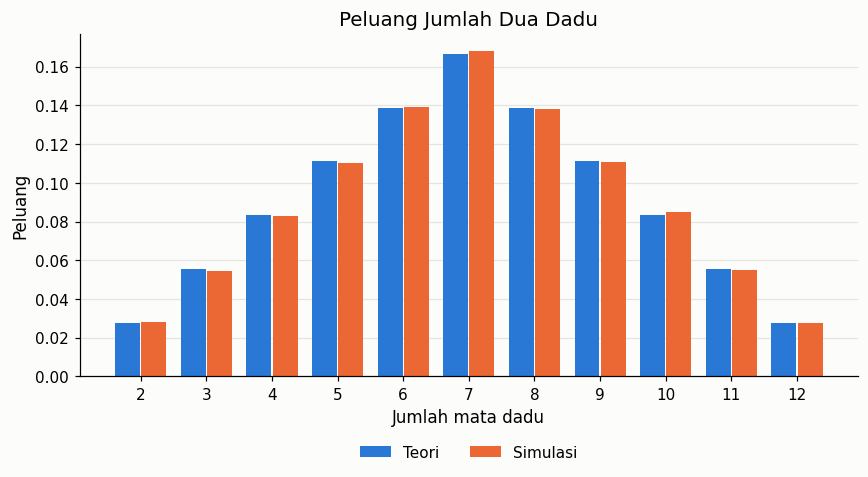

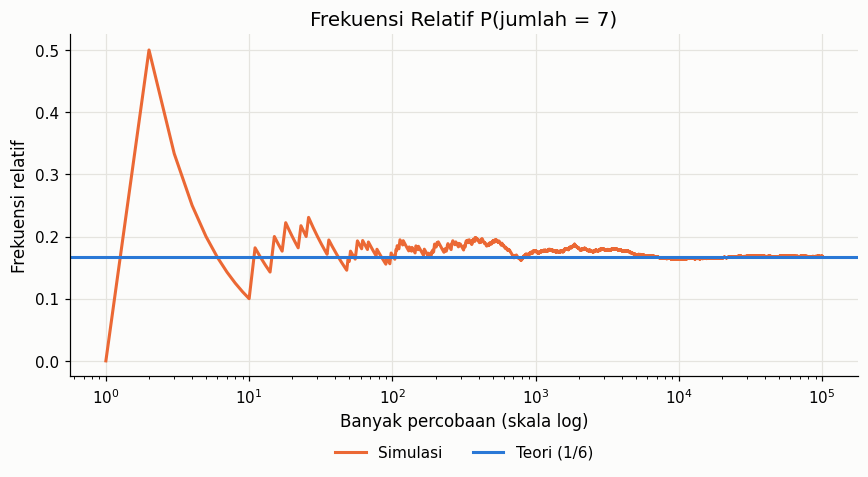

In [5]:
# Grafik distribusi jumlah dua dadu
nilai_jumlah = list(range(2, 13))
teori = [sum(sum(h) == s for h in ruang_sampel) / 36 for s in nilai_jumlah]
simulasi = [(jumlah == s).mean() for s in nilai_jumlah]
grafik_batang(nilai_jumlah, teori, simulasi, "Peluang Jumlah Dua Dadu", "Jumlah mata dadu")

# Grafik perubahan frekuensi relatif seiring bertambahnya percobaan
percobaan = np.arange(1, N + 1)
frekuensi = np.cumsum(jumlah == 7) / percobaan
fig, ax = plt.subplots()
ax.plot(percobaan, frekuensi, color=WARNA_SIMULASI, linewidth=2, label="Simulasi")
ax.axhline(1 / 6, color=WARNA_TEORI, linewidth=2, label="Teori (1/6)")
ax.set_xscale("log")
ax.set(title="Frekuensi Relatif P(jumlah = 7)", xlabel="Banyak percobaan (skala log)",
       ylabel="Frekuensi relatif")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout()
plt.show()

## A2. Kombinasi: Pemilihan Server

**Soal:** Terdapat 10 server dan 2 di antaranya rusak. Dipilih 3 server secara acak. Berapa peluang ketiganya sehat?

**Hitungan manual:**

$$P(\text{semua sehat})=\frac{\binom{8}{3}}{\binom{10}{3}}=\frac{56}{120}=\frac{7}{15}\approx 0{,}4667$$

In [6]:
# Perhitungan kombinasi dengan math
cara_sehat = math.comb(8, 3)
cara_total = math.comb(10, 3)
peluang_math = Fraction(cara_sehat, cara_total)

# Perhitungan dengan distribusi hipergeometrik: populasi 10, rusak 2, sampel 3
distribusi_server = stats.hypergeom(M=10, n=2, N=3)
peluang_scipy = distribusi_server.pmf(0)

# Simulasi: server 0 dan 1 dianggap rusak, lalu diambil 3 server pertama setelah diacak
urutan_server = rng.permuted(np.tile(np.arange(10), (N, 1)), axis=1)[:, :3]
banyak_rusak = (urutan_server < 2).sum(axis=1)
peluang_simulasi = (banyak_rusak == 0).mean()

print("C(8,3)        :", cara_sehat)
print("C(10,3)       :", cara_total)
print("Hasil math    :", peluang_math)
print(f"Hasil SciPy   : {peluang_scipy:.4f}")
tabel_banding([["P(semua sehat)", 7 / 15, float(peluang_math), peluang_simulasi]])

C(8,3)        : 56
C(10,3)       : 120
Hasil math    : 7/15
Hasil SciPy   : 0.4667


,Besaran,Manual,Python,Simulasi,Selisih
0,P(semua sehat),0.4667,0.4667,0.4636,0.0031


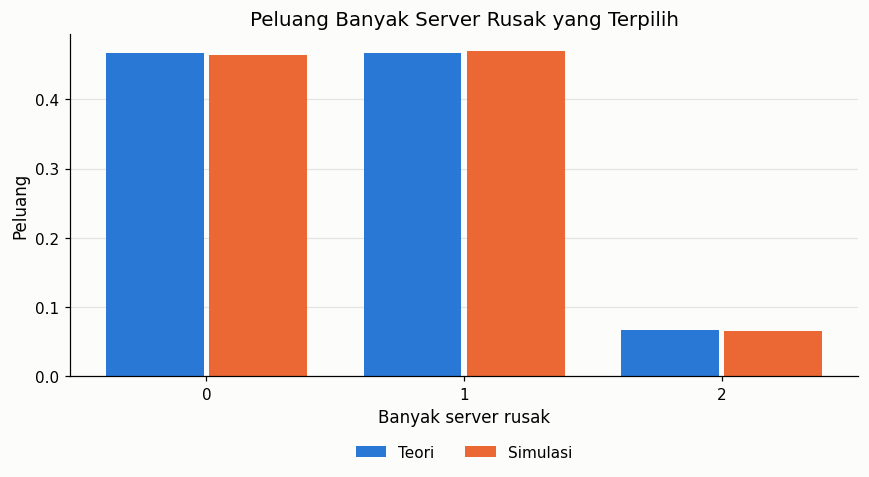

In [7]:
# Grafik peluang banyak server rusak yang terpilih
nilai_x = [0, 1, 2]
simulasi = [(banyak_rusak == x).mean() for x in nilai_x]
grafik_batang(nilai_x, distribusi_server.pmf(nilai_x), simulasi,
              "Peluang Banyak Server Rusak yang Terpilih", "Banyak server rusak")

## A3. Gabungan Kejadian: Bug Frontend dan Backend

**Soal:** $P(F)=0{,}3$, $P(B)=0{,}4$, dan $P(F\cap B)=0{,}1$. Berapa peluang terjadi minimal satu bug?

**Hitungan manual:**

$$P(F\cup B)=P(F)+P(B)-P(F\cap B)=0{,}3+0{,}4-0{,}1=0{,}6$$

In [8]:
# Menjaga hasil tetap eksak dengan Fraction
p_frontend = Fraction(3, 10)
p_backend = Fraction(4, 10)
p_keduanya = Fraction(1, 10)
p_gabungan = p_frontend + p_backend - p_keduanya

# Simulasi dengan membagi rentang 0 sampai 1 sesuai peluang tiap kejadian:
# 0,2 hanya frontend; 0,1 keduanya; 0,3 hanya backend; 0,4 tanpa bug
acak = rng.random(N)
bug_frontend = acak < 0.3
bug_backend = (acak >= 0.2) & (acak < 0.6)
peluang_simulasi = (bug_frontend | bug_backend).mean()

print("P(F atau B) eksak :", p_gabungan)
tabel_banding([
    ["P(F)", 0.3, float(p_frontend), bug_frontend.mean()],
    ["P(B)", 0.4, float(p_backend), bug_backend.mean()],
    ["P(F dan B)", 0.1, float(p_keduanya), (bug_frontend & bug_backend).mean()],
    ["P(F atau B)", 0.6, float(p_gabungan), peluang_simulasi],
])

P(F atau B) eksak : 3/5


,Besaran,Manual,Python,Simulasi,Selisih
0,P(F),0.3000,0.3000,0.3011,0.0011
1,P(B),0.4000,0.4000,0.3978,0.0022
2,P(F dan B),0.1000,0.1000,0.1000,0.0000
3,P(F atau B),0.6000,0.6000,0.5990,0.0010


## A4. Probabilitas Bersyarat: Bug per Modul

**Soal:** Modul A memiliki 30 bug dari 200 commit. Modul B memiliki 30 bug dari 300 commit. Berapa peluang bug pada tiap modul? Hitung juga interval kepercayaan 95% untuk modul A.

**Hitungan manual:**

$$P(\text{bug}\mid A)=\frac{30}{200}=0{,}15 \qquad P(\text{bug}\mid B)=\frac{30}{300}=0{,}10$$

$$P(\text{bug})=\frac{60}{500}=0{,}12$$

In [9]:
# Menyusun data commit dalam tabel Pandas
data_commit = pd.DataFrame({
    "modul": ["A"] * 200 + ["B"] * 300,
    "bug": [1] * 30 + [0] * 170 + [1] * 30 + [0] * 270,
})
peluang_modul = data_commit.groupby("modul")["bug"].mean()
tabel_peluang = pd.crosstab(
    data_commit["modul"],
    data_commit["bug"].map({1: "Bug", 0: "Tidak bug"}),
    normalize="index",
)

# Simulasi: mengambil commit acak dari data
indeks = rng.integers(0, len(data_commit), size=N)
sampel = data_commit.iloc[indeks]
simulasi_modul = sampel.groupby("modul")["bug"].mean()

# Interval kepercayaan Wilson 95% untuk modul A
batas_bawah, batas_atas = proportion_confint(30, 200, alpha=0.05, method="wilson")

print("Peluang bersyarat per modul:")
display(tabel_peluang)
print(f"Interval kepercayaan Wilson 95% modul A: {batas_bawah:.4f} sampai {batas_atas:.4f}")
tabel_banding([
    ["P(bug | A)", 0.15, peluang_modul["A"], simulasi_modul["A"]],
    ["P(bug | B)", 0.10, peluang_modul["B"], simulasi_modul["B"]],
    ["P(bug)", 0.12, data_commit["bug"].mean(), sampel["bug"].mean()],
])

Peluang bersyarat per modul:


bug,Bug,Tidak bug
modul,,
A,0.1500,0.8500
B,0.1000,0.9000


Interval kepercayaan Wilson 95% modul A: 0.1071 sampai 0.2061


,Besaran,Manual,Python,Simulasi,Selisih
0,P(bug | A),0.1500,0.1500,0.1502,0.0002
1,P(bug | B),0.1000,0.1000,0.1007,0.0007
2,P(bug),0.1200,0.1200,0.1204,0.0004


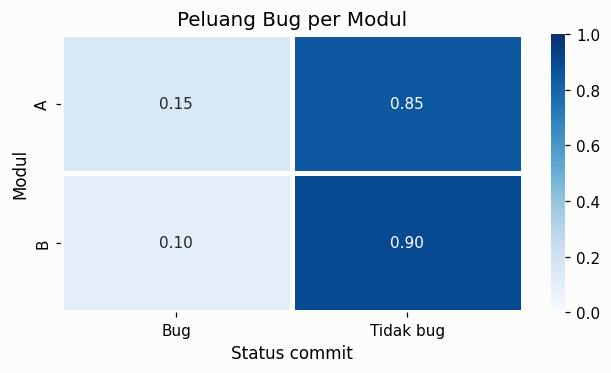

In [10]:
# Heatmap peluang bersyarat
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.heatmap(tabel_peluang, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            linewidths=2, linecolor="#fcfcfb", ax=ax)
ax.set(title="Peluang Bug per Modul", xlabel="Status commit", ylabel="Modul")
plt.tight_layout()
plt.show()

## A5. Kejadian Saling Bebas: Server Cadangan

**Soal:** Dua server bekerja saling bebas. Peluang gagalnya 0,1 dan 0,2. Layanan mati hanya jika keduanya gagal. Berapa peluang layanan tetap hidup?

**Hitungan manual:**

$$P(\text{hidup})=1-P(G_1)P(G_2)=1-(0{,}1)(0{,}2)=0{,}98$$

In [11]:
# Perhitungan eksak
p_gagal_1 = Fraction(1, 10)
p_gagal_2 = Fraction(1, 5)
p_hidup = 1 - p_gagal_1 * p_gagal_2

# Simulasi dua server yang saling bebas
gagal_1 = rng.random(N) < 0.1
gagal_2 = rng.random(N) < 0.2
peluang_simulasi = 1 - (gagal_1 & gagal_2).mean()

print("P(layanan hidup) eksak :", p_hidup)
tabel_banding([
    ["P(keduanya gagal)", 0.02, float(p_gagal_1 * p_gagal_2), (gagal_1 & gagal_2).mean()],
    ["P(layanan hidup)", 0.98, float(p_hidup), peluang_simulasi],
])

P(layanan hidup) eksak : 49/50


,Besaran,Manual,Python,Simulasi,Selisih
0,P(keduanya gagal),0.0200,0.0200,0.0199,0.0001
1,P(layanan hidup),0.9800,0.9800,0.9801,0.0001


## A6. Probabilitas Total: Error pada Tiga Server

**Soal:** Server 1, 2, dan 3 melayani 50%, 30%, dan 20% trafik, dengan peluang error 1%, 2%, dan 5%. Berapa peluang satu request mengalami error, dan berapa kontribusi tiap server?

**Hitungan manual:**

$$P(E)=\sum_{i=1}^{3}P(S_i)P(E\mid S_i)=(0{,}5)(0{,}01)+(0{,}3)(0{,}02)+(0{,}2)(0{,}05)=0{,}021$$

$$P(S_3\mid E)=\frac{(0{,}2)(0{,}05)}{0{,}021}=\frac{10}{21}\approx 0{,}4762$$

In [12]:
# Data server
trafik = [Fraction(1, 2), Fraction(3, 10), Fraction(1, 5)]
peluang_error = [Fraction(1, 100), Fraction(2, 100), Fraction(5, 100)]

# Hukum probabilitas total dan kontribusi tiap server
p_error = sum(t * e for t, e in zip(trafik, peluang_error))
kontribusi = [t * e / p_error for t, e in zip(trafik, peluang_error)]

# Simulasi: memilih server, lalu menentukan apakah request error
server = rng.choice(3, size=N, p=[0.5, 0.3, 0.2])
error = rng.random(N) < np.array([0.01, 0.02, 0.05])[server]
kontribusi_simulasi = [(server[error] == i).mean() for i in range(3)]

print("P(error) eksak         :", p_error)
print("Kontribusi tiap server :", [str(k) for k in kontribusi])
tabel_banding([
    ["P(error)", 0.021, float(p_error), error.mean()],
    ["P(S1 | error)", 5 / 21, float(kontribusi[0]), kontribusi_simulasi[0]],
    ["P(S2 | error)", 6 / 21, float(kontribusi[1]), kontribusi_simulasi[1]],
    ["P(S3 | error)", 10 / 21, float(kontribusi[2]), kontribusi_simulasi[2]],
])

P(error) eksak         : 21/1000
Kontribusi tiap server : ['5/21', '2/7', '10/21']


,Besaran,Manual,Python,Simulasi,Selisih
0,P(error),0.0210,0.0210,0.0207,0.0003
1,P(S1 | error),0.2381,0.2381,0.2407,0.0026
2,P(S2 | error),0.2857,0.2857,0.2847,0.0010
3,P(S3 | error),0.4762,0.4762,0.4746,0.0016


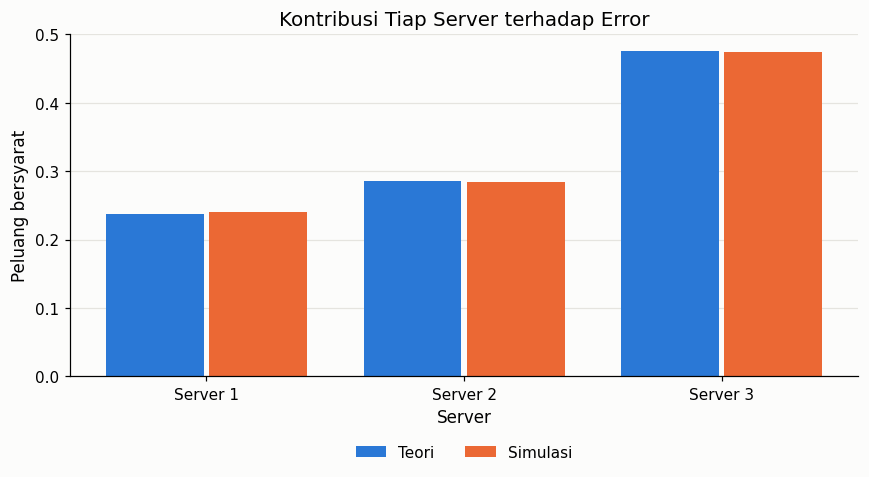

In [13]:
# Grafik kontribusi error tiap server
grafik_batang(["Server 1", "Server 2", "Server 3"], [float(k) for k in kontribusi], kontribusi_simulasi,
              "Kontribusi Tiap Server terhadap Error", "Server", "Peluang bersyarat")

## A7. Teorema Bayes: Filter Spam

**Soal:** Sebanyak 20% email adalah spam. Suatu kata muncul pada 70% spam dan 5% email bukan spam. Jika kata tersebut muncul, berapa peluang email itu spam?

**Hitungan manual:**

$$P(S\mid K)=\frac{P(K\mid S)P(S)}{P(K\mid S)P(S)+P(K\mid S^c)P(S^c)}=\frac{(0{,}7)(0{,}2)}{(0{,}7)(0{,}2)+(0{,}05)(0{,}8)}=\frac{0{,}14}{0{,}18}=\frac{7}{9}\approx 0{,}7778$$

In [14]:
# Perhitungan eksak Teorema Bayes
p_spam = Fraction(1, 5)
p_kata_spam = Fraction(7, 10)
p_kata_bukan = Fraction(1, 20)
p_kata = p_kata_spam * p_spam + p_kata_bukan * (1 - p_spam)
p_spam_kata = p_kata_spam * p_spam / p_kata

# Simulasi email
email_spam = rng.random(N) < 0.2
ada_kata = rng.random(N) < np.where(email_spam, 0.7, 0.05)
peluang_simulasi = email_spam[ada_kata].mean()

print("P(kata) eksak        :", p_kata)
print("P(spam | kata) eksak :", p_spam_kata)
tabel_banding([
    ["P(kata)", 0.18, float(p_kata), ada_kata.mean()],
    ["P(spam | kata)", 7 / 9, float(p_spam_kata), peluang_simulasi],
])

P(kata) eksak        : 9/50
P(spam | kata) eksak : 7/9


,Besaran,Manual,Python,Simulasi,Selisih
0,P(kata),0.1800,0.1800,0.1792,0.0008
1,P(spam | kata),0.7778,0.7778,0.7792,0.0014


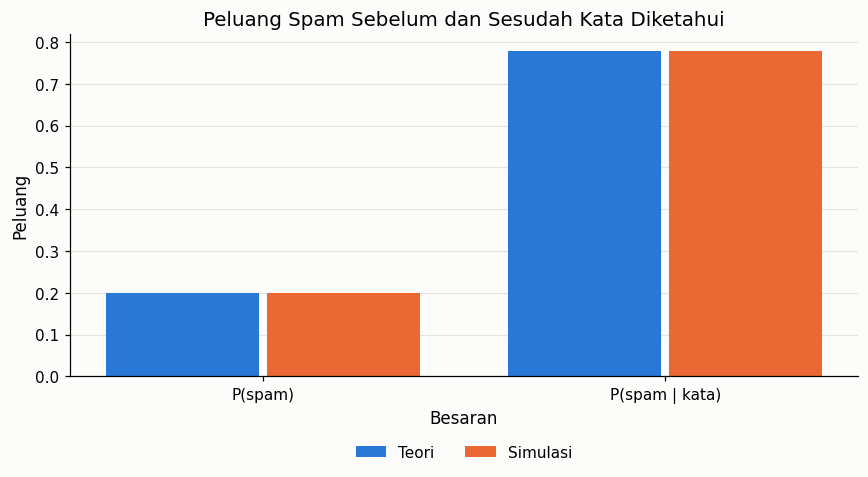

In [15]:
# Grafik peluang sebelum dan sesudah kata diketahui
grafik_batang(["P(spam)", "P(spam | kata)"], [float(p_spam), float(p_spam_kata)],
              [email_spam.mean(), peluang_simulasi], "Peluang Spam Sebelum dan Sesudah Kata Diketahui"
              , "Besaran")

## A8. Paradoks Ulang Tahun: Tabrakan Hash

**Soal:** Sebanyak 23 data dimasukkan secara acak ke 365 slot hash. Berapa peluang minimal dua data masuk slot yang sama?

**Hitungan manual:** Gunakan komplemen, yaitu peluang semua data menempati slot berbeda.

$$P(\text{tabrakan})=1-\frac{365\times364\times\cdots\times343}{365^{23}}\approx 0{,}5073$$

In [16]:
# Fungsi peluang tabrakan
def peluang_tabrakan(banyak_data, banyak_slot=365):
    return 1 - math.perm(banyak_slot, banyak_data) / banyak_slot ** banyak_data


peluang_python = peluang_tabrakan(23)

# Simulasi: mengurutkan slot, lalu mencari nilai berdekatan yang sama
slot = np.sort(rng.integers(0, 365, size=(N, 23)), axis=1)
ada_tabrakan = (np.diff(slot, axis=1) == 0).any(axis=1)

tabel_banding([["P(tabrakan), 23 data", 0.5073, peluang_python, ada_tabrakan.mean()]])

,Besaran,Manual,Python,Simulasi,Selisih
0,"P(tabrakan), 23 data",0.5073,0.5073,0.5079,0.0006


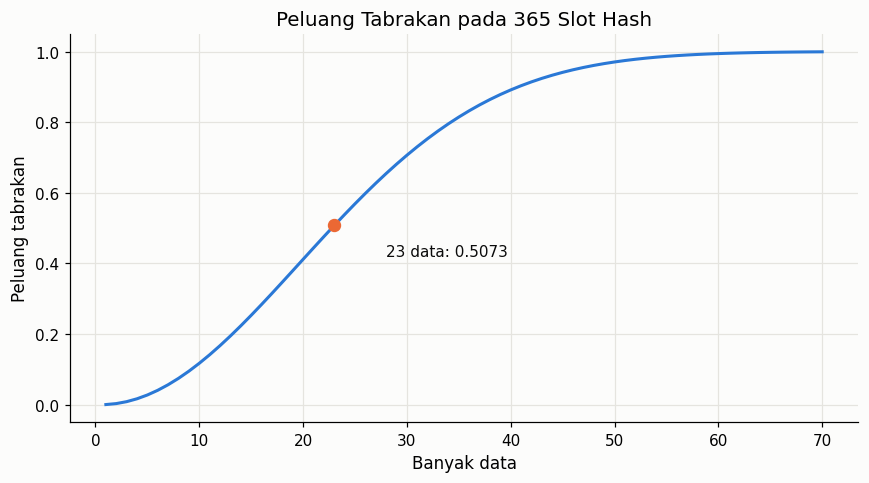

In [17]:
# Grafik peluang tabrakan untuk berbagai banyak data
banyak_data = np.arange(1, 71)
peluang = [peluang_tabrakan(int(n)) for n in banyak_data]

fig, ax = plt.subplots()
ax.plot(banyak_data, peluang, color=WARNA_TEORI, linewidth=2)
ax.scatter([23], [peluang_python], color=WARNA_SIMULASI, s=60, zorder=3)
ax.annotate(f"23 data: {peluang_python:.4f}", (23, peluang_python), xytext=(28, 0.42), color="#0b0b0b")
ax.set(title="Peluang Tabrakan pada 365 Slot Hash", xlabel="Banyak data", ylabel="Peluang tabrakan")
plt.tight_layout()
plt.show()

## A9. Simulasi Acak: Monty Hall

**Soal:** Terdapat 3 pintu dan satu hadiah. Setelah peserta memilih, pembawa acara membuka satu pintu kosong yang tidak dipilih. Mana yang lebih baik, tetap atau ganti pilihan?

**Hitungan manual:** Pilihan awal benar dengan peluang $\frac{1}{3}$. Strategi ganti menang saat pilihan awal salah.

$$P(\text{menang}\mid\text{tetap})=\frac{1}{3}\approx0{,}3333 \qquad P(\text{menang}\mid\text{ganti})=\frac{2}{3}\approx0{,}6667$$

In [18]:
# Simulasi dengan random dan Counter
menang = Counter()

for _ in range(N):
    hadiah = random.randrange(3)
    pilihan = random.randrange(3)

    # Tetap menang jika pilihan awal benar, ganti menang jika pilihan awal salah
    if pilihan == hadiah:
        menang["tetap"] += 1
    else:
        menang["ganti"] += 1

peluang_tetap = menang["tetap"] / N
peluang_ganti = menang["ganti"] / N

print("Jumlah kemenangan:", dict(menang))
tabel_banding([
    ["P(menang | tetap)", 1 / 3, float(Fraction(1, 3)), peluang_tetap],
    ["P(menang | ganti)", 2 / 3, float(Fraction(2, 3)), peluang_ganti],
])

Jumlah kemenangan: {'ganti': 66544, 'tetap': 33456}


,Besaran,Manual,Python,Simulasi,Selisih
0,P(menang | tetap),0.3333,0.3333,0.3346,0.0012
1,P(menang | ganti),0.6667,0.6667,0.6654,0.0012


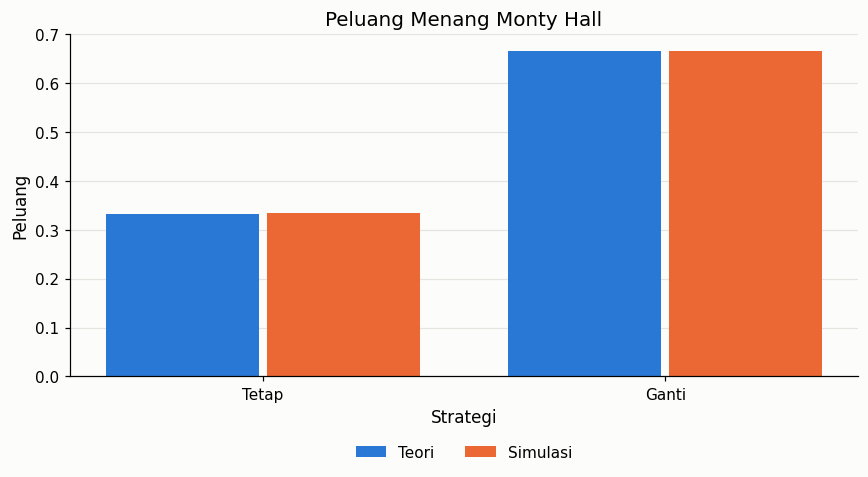

In [19]:
# Grafik perbandingan strategi
grafik_batang(["Tetap", "Ganti"], [1 / 3, 2 / 3], [peluang_tetap, peluang_ganti],
              "Peluang Menang Monty Hall", "Strategi")

# Bagian B: Distribusi Probabilitas

## Distribusi Diskrit

## B1. Bernoulli: Status Login

**Soal:** Satu percobaan login berhasil dengan $p=0{,}9$. Tentukan $P(X=1)$, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X=1)=0{,}9 \qquad E[X]=p=0{,}9 \qquad \mathrm{Var}(X)=p(1-p)=0{,}09$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X = 1),0.9000,0.9000,0.9010,0.0010
1,E[X],0.9000,0.9000,0.9010,0.0010
2,Var(X),0.0900,0.0900,0.0892,0.0008


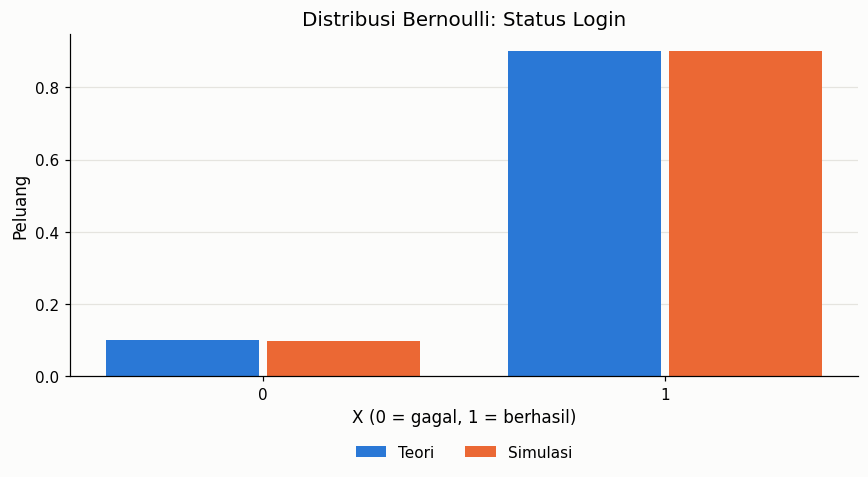

In [20]:
# Teori dengan SciPy dan simulasi dengan NumPy
login = stats.bernoulli(0.9)
sampel = rng.binomial(1, 0.9, size=N)

tabel_banding([
    ["P(X = 1)", 0.9, login.pmf(1), (sampel == 1).mean()],
    ["E[X]", 0.9, login.mean(), sampel.mean()],
    ["Var(X)", 0.09, login.var(), sampel.var()],
])
grafik_diskrit(login, sampel, [0, 1], "Distribusi Bernoulli: Status Login",
               "X (0 = gagal, 1 = berhasil)")

## B2. Uniform Diskrit: Digit OTP

**Soal:** Satu digit OTP dipilih acak dari 0 sampai 9. Tentukan $P(X\ge7)$, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X\ge7)=\frac{3}{10}=0{,}3 \qquad E[X]=\frac{0+9}{2}=4{,}5 \qquad \mathrm{Var}(X)=\frac{10^2-1}{12}=8{,}25$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X >= 7),0.3000,0.3000,0.2995,0.0005
1,E[X],4.5000,4.5000,4.4931,0.0069
2,Var(X),8.2500,8.2500,8.2420,0.0080


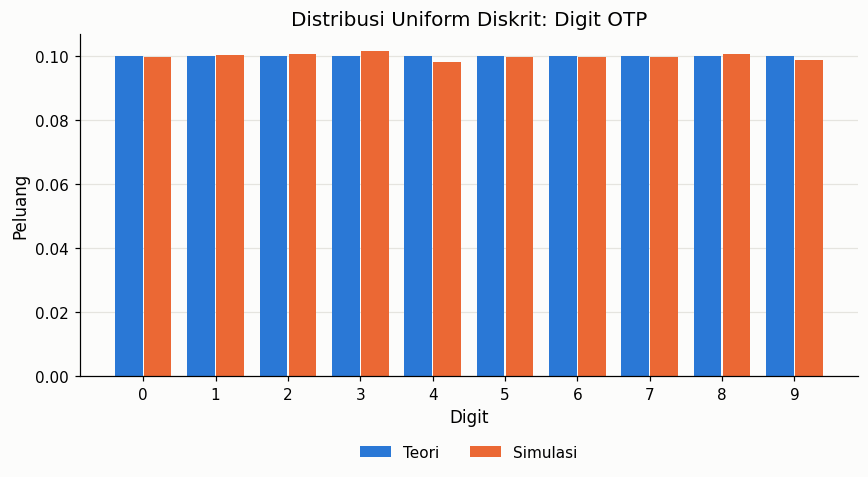

In [21]:
# Pada SciPy, randint(0, 10) menghasilkan bilangan bulat 0 sampai 9
digit = stats.randint(0, 10)
sampel = rng.integers(0, 10, size=N)

tabel_banding([
    ["P(X >= 7)", 0.3, digit.sf(6), (sampel >= 7).mean()],
    ["E[X]", 4.5, digit.mean(), sampel.mean()],
    ["Var(X)", 8.25, digit.var(), sampel.var()],
])
grafik_diskrit(digit, sampel, list(range(10)), "Distribusi Uniform Diskrit: Digit OTP", "Digit")

## B3. Binomial: Paket Data Rusak

**Soal:** Terdapat 10 paket data. Setiap paket rusak dengan $p=0{,}05$. Tentukan peluang tepat 2 paket rusak, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X=2)=\binom{10}{2}(0{,}05)^2(0{,}95)^8\approx0{,}0746$$

$$E[X]=np=0{,}5 \qquad \mathrm{Var}(X)=np(1-p)=0{,}475$$

P(X = 2) eksak SymPy : 152852067369/2048000000000
E[X] eksak SymPy     : 1/2
Var(X) eksak SymPy   : 19/40


,Besaran,Manual,Python,Simulasi,Selisih
0,P(X = 2),0.0746,0.0746,0.0745,0.0001
1,E[X],0.5000,0.5000,0.4981,0.0019
2,Var(X),0.4750,0.4750,0.4719,0.0031


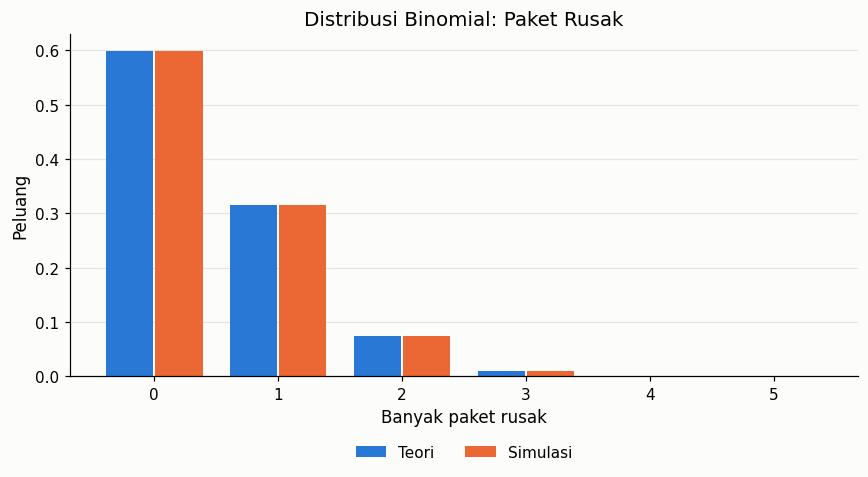

In [22]:
# Teori dengan SciPy dan simulasi dengan NumPy
paket = stats.binom(10, 0.05)
sampel = rng.binomial(10, 0.05, size=N)

# Nilai eksak dengan SymPy
X_simbolik = Binomial("X", 10, Rational(1, 20))
print("P(X = 2) eksak SymPy :", P_simbolik(Eq(X_simbolik, 2)))
print("E[X] eksak SymPy     :", E_simbolik(X_simbolik))
print("Var(X) eksak SymPy   :", var_simbolik(X_simbolik))

tabel_banding([
    ["P(X = 2)", 0.0746, paket.pmf(2), (sampel == 2).mean()],
    ["E[X]", 0.5, paket.mean(), sampel.mean()],
    ["Var(X)", 0.475, paket.var(), sampel.var()],
])
grafik_diskrit(paket, sampel, list(range(6)), "Distribusi Binomial: Paket Rusak", "Banyak paket rusak")

## B4. Geometrik: Percobaan Koneksi

**Soal:** Peluang koneksi berhasil adalah $p=0{,}3$ pada setiap percobaan. Tentukan peluang berhasil paling lambat pada percobaan ke-3, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X\le3)=1-(1-p)^3=1-0{,}7^3=0{,}657$$

$$E[X]=\frac{1}{p}\approx3{,}3333 \qquad \mathrm{Var}(X)=\frac{1-p}{p^2}\approx7{,}7778$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X <= 3),0.6570,0.6570,0.6580,0.0010
1,E[X],3.3333,3.3333,3.3216,0.0117
2,Var(X),7.7778,7.7778,7.7172,0.0606


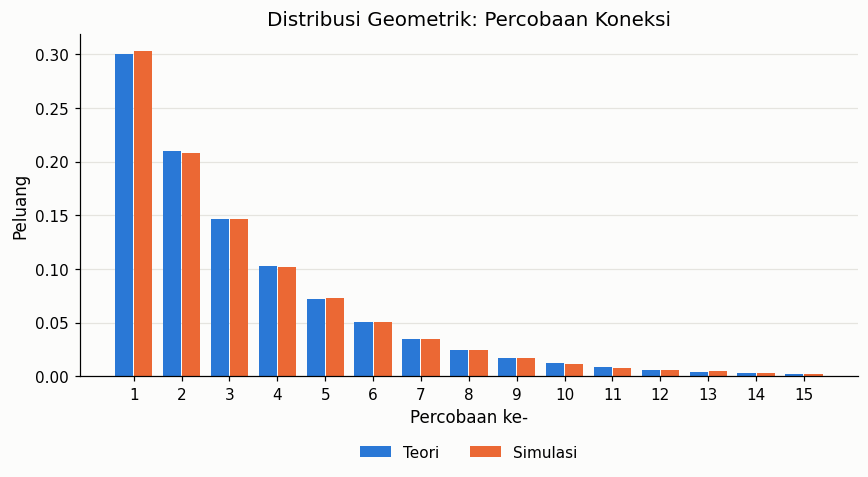

In [23]:
# X adalah nomor percobaan saat koneksi pertama kali berhasil
koneksi = stats.geom(0.3)
sampel = rng.geometric(0.3, size=N)

tabel_banding([
    ["P(X <= 3)", 0.657, koneksi.cdf(3), (sampel <= 3).mean()],
    ["E[X]", 10 / 3, koneksi.mean(), sampel.mean()],
    ["Var(X)", 0.7 / 0.3 ** 2, koneksi.var(), sampel.var()],
])
grafik_diskrit(koneksi, sampel, list(range(1, 16)), "Distribusi Geometrik: Percobaan Koneksi", "Percobaan ke-")

## B5. Hipergeometrik: Pemeriksaan Malware

**Soal:** Dari 100 file, 5 berisi malware. Diambil 10 file tanpa pengembalian. Tentukan peluang tepat 1 file malware, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X=1)=\frac{\binom{5}{1}\binom{95}{9}}{\binom{100}{10}}\approx0{,}3394$$

$$E[X]=n\frac{K}{N}=0{,}5 \qquad \mathrm{Var}(X)=n\frac{K}{N}\left(1-\frac{K}{N}\right)\frac{N-n}{N-1}\approx0{,}4318$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X = 1),0.3394,0.3394,0.3377,0.0017
1,E[X],0.5000,0.5000,0.5008,0.0008
2,Var(X),0.4318,0.4318,0.4339,0.0021


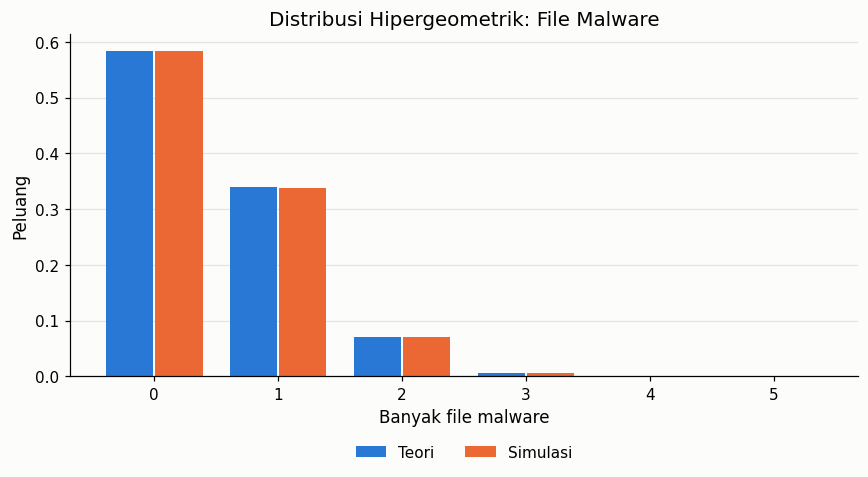

In [24]:
# M = populasi, n = jumlah malware, N = banyak file yang diambil
malware = stats.hypergeom(M=100, n=5, N=10)
sampel = rng.hypergeometric(ngood=5, nbad=95, nsample=10, size=N)

manual_var = 10 * 0.05 * 0.95 * 90 / 99

tabel_banding([
    ["P(X = 1)", 0.3394, malware.pmf(1), (sampel == 1).mean()],
    ["E[X]", 0.5, malware.mean(), sampel.mean()],
    ["Var(X)", manual_var, malware.var(), sampel.var()],
])
grafik_diskrit(malware, sampel, list(range(6)), "Distribusi Hipergeometrik: "
+"File Malware", "Banyak file malware")

## B6. Poisson: Error per Menit

**Soal:** Rata-rata terjadi 2 error per menit. Tentukan peluang tepat 3 error dalam satu menit, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X=3)=\frac{e^{-2}2^3}{3!}\approx0{,}1804 \qquad E[X]=\lambda=2 \qquad \mathrm{Var}(X)=\lambda=2$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X = 3),0.1804,0.1804,0.1804,0.0000
1,E[X],2.0000,2.0000,1.9921,0.0079
2,Var(X),2.0000,2.0000,1.9886,0.0114


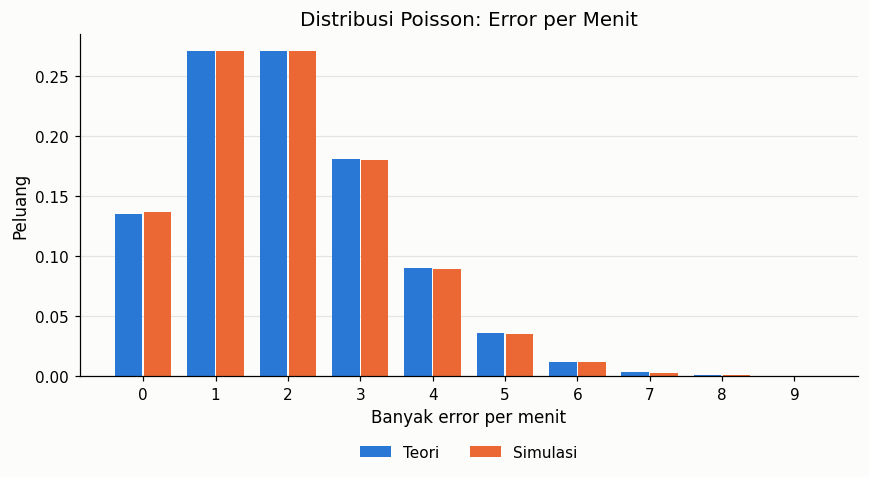

In [25]:
# Teori dengan SciPy dan simulasi dengan NumPy
error_menit = stats.poisson(2)
sampel = rng.poisson(2, size=N)

tabel_banding([
    ["P(X = 3)", 0.1804, error_menit.pmf(3), (sampel == 3).mean()],
    ["E[X]", 2, error_menit.mean(), sampel.mean()],
    ["Var(X)", 2, error_menit.var(), sampel.var()],
])
grafik_diskrit(error_menit, sampel, list(range(10)), "Distribusi Poisson: Error per Menit",
               "Banyak error per menit")

## Distribusi Kontinu

## B7. Uniform: Latensi Jaringan

**Soal:** Latensi menyebar merata pada 10 sampai 50 ms. Tentukan $P(X<20)$, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X<20)=\frac{20-10}{50-10}=0{,}25 \qquad E[X]=\frac{10+50}{2}=30 \qquad \mathrm{Var}(X)=\frac{(50-10)^2}{12}\approx133{,}3333$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X < 20),0.2500,0.2500,0.2487,0.0013
1,E[X],30.0000,30.0000,30.0366,0.0366
2,Var(X),133.3333,133.3333,133.3732,0.0398


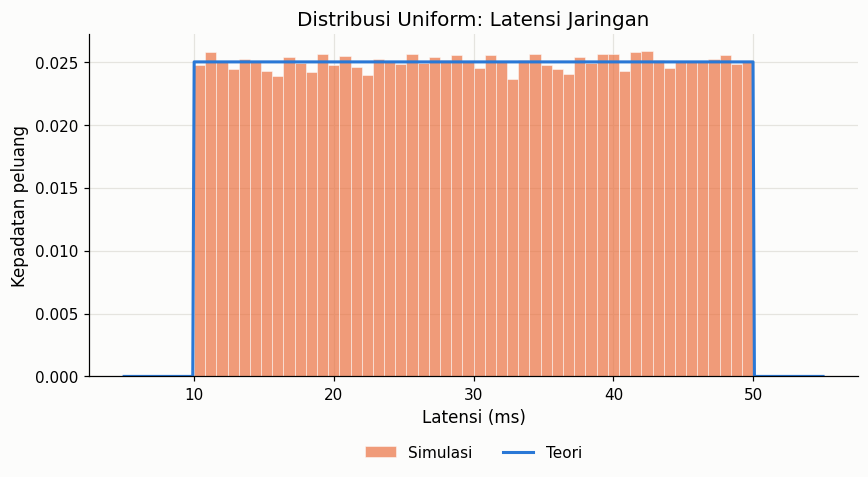

In [26]:
# Pada SciPy, loc adalah batas bawah dan scale adalah lebar rentang
latensi = stats.uniform(loc=10, scale=40)
sampel = rng.uniform(10, 50, size=N)

tabel_banding([
    ["P(X < 20)", 0.25, latensi.cdf(20), (sampel < 20).mean()],
    ["E[X]", 30, latensi.mean(), sampel.mean()],
    ["Var(X)", 1600 / 12, latensi.var(), sampel.var()],
])
grafik_kontinu(latensi, sampel, np.linspace(5, 55, 500), "Distribusi Uniform: Latensi Jaringan",
               "Latensi (ms)")

## B8. Normal: Response Time

**Soal:** Response time berdistribusi normal dengan $\mu=100$ ms dan $\sigma=15$ ms. Tentukan $P(X>120)$ dan ambang persentil ke-95.

**Hitungan manual:**

$$z=\frac{120-100}{15}\approx1{,}3333 \qquad P(X>120)=1-\Phi(1{,}3333)\approx1-0{,}9088=0{,}0912$$

$$x_{0{,}95}=\mu+1{,}6449\,\sigma=100+1{,}6449(15)\approx124{,}67 \text{ ms}$$

$$E[X]=100 \qquad \mathrm{Var}(X)=15^2=225$$

P(X > 120) NormalDist    : 0.0912
Persentil 95 NormalDist  : 124.6728


,Besaran,Manual,Python,Simulasi,Selisih
0,P(X > 120),0.0912,0.0912,0.0913,0.0001
1,Persentil ke-95,124.6700,124.6728,124.7037,0.0309
2,E[X],100.0000,100.0000,100.0269,0.0269
3,Var(X),225.0000,225.0000,226.1783,1.1783


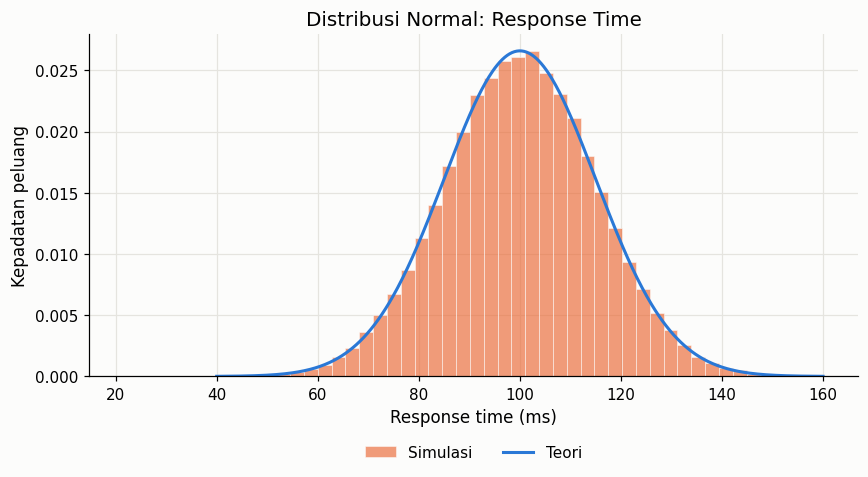

In [27]:
# Pada SciPy, loc adalah rata-rata dan scale adalah simpangan baku
respon = stats.norm(loc=100, scale=15)
sampel = rng.normal(100, 15, size=N)

# Pembanding dengan NormalDist dari library statistics
respon_bawaan = NormalDist(100, 15)
print(f"P(X > 120) NormalDist    : {1 - respon_bawaan.cdf(120):.4f}")
print(f"Persentil 95 NormalDist  : {respon_bawaan.inv_cdf(0.95):.4f}")

tabel_banding([
    ["P(X > 120)", 0.0912, respon.sf(120), (sampel > 120).mean()],
    ["Persentil ke-95", 124.67, respon.ppf(0.95), np.percentile(sampel, 95)],
    ["E[X]", 100, respon.mean(), sampel.mean()],
    ["Var(X)", 225, respon.var(), sampel.var()],
])
grafik_kontinu(respon, sampel, np.linspace(40, 160, 500), "Distribusi Normal: Response Time",
               "Response time (ms)")

## B9. Eksponensial: Jeda Antar-Request

**Soal:** Rata-rata jeda antar-request adalah 2 detik, sehingga $\lambda=0{,}5$ per detik. Tentukan $P(X>2)$, nilai harapan, dan varians.

**Hitungan manual:**

$$P(X>2)=e^{-\lambda x}=e^{-(0{,}5)(2)}=e^{-1}\approx0{,}3679 \qquad E[X]=\frac{1}{\lambda}=2 \qquad \mathrm{Var}(X)=\frac{1}{\lambda^2}=4$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X > 2),0.3679,0.3679,0.3674,0.0005
1,E[X],2.0000,2.0000,1.9998,0.0002
2,Var(X),4.0000,4.0000,3.9790,0.0210


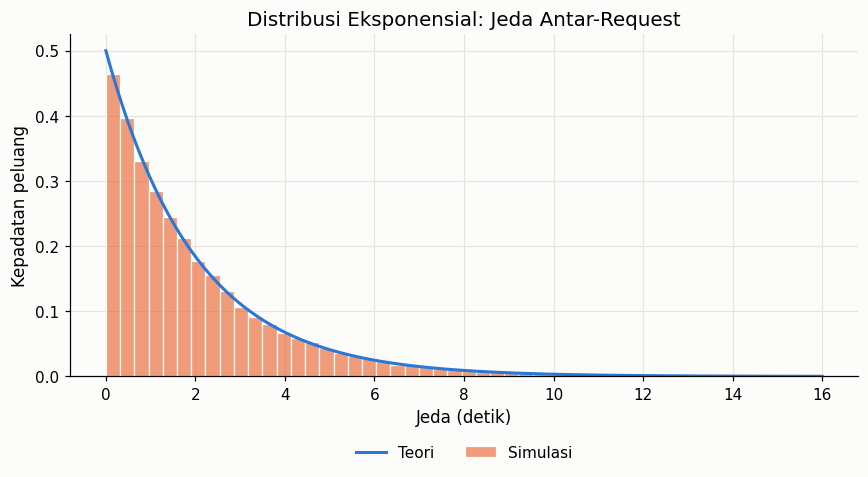

In [28]:
# Pada SciPy dan NumPy, scale adalah 1/lambda
jeda = stats.expon(scale=2)
sampel = rng.exponential(2, size=N)

tabel_banding([
    ["P(X > 2)", math.exp(-1), jeda.sf(2), (sampel > 2).mean()],
    ["E[X]", 2, jeda.mean(), sampel.mean()],
    ["Var(X)", 4, jeda.var(), sampel.var()],
])

# Histogram dengan Seaborn dan kurva teori
nilai_x = np.linspace(0, 16, 500)
fig, ax = plt.subplots()
sns.histplot(sampel[sampel <= 16], bins=50, stat="density", color=WARNA_SIMULASI, alpha=0.65,
             edgecolor="#fcfcfb", label="Simulasi", ax=ax)
ax.plot(nilai_x, jeda.pdf(nilai_x), color=WARNA_TEORI, linewidth=2, label="Teori")
ax.set(title="Distribusi Eksponensial: Jeda Antar-Request", xlabel="Jeda (detik)", ylabel="Kepadatan peluang")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout()
plt.show()

## B10. Segitiga: Estimasi Pengerjaan Fitur

**Soal:** Pengerjaan fitur tercepat $a=2$ hari, paling mungkin $c=4$ hari, dan terlama $b=10$ hari. Tentukan peluang pengerjaan lebih dari 7 hari, nilai harapan, dan varians.

**Hitungan manual:** Karena $7>c$, gunakan rumus ekor kanan.

$$P(X>7)=\frac{(b-7)^2}{(b-a)(b-c)}=\frac{3^2}{(8)(6)}=\frac{9}{48}=0{,}1875$$

$$E[X]=\frac{a+b+c}{3}\approx5{,}3333 \qquad \mathrm{Var}(X)=\frac{a^2+b^2+c^2-ab-ac-bc}{18}=\frac{52}{18}\approx2{,}8889$$

,Besaran,Manual,Python,Simulasi,Selisih
0,P(X > 7),0.1875,0.1875,0.1890,0.0015
1,E[X],5.3333,5.3333,5.3375,0.0041
2,Var(X),2.8889,2.8889,2.9001,0.0112


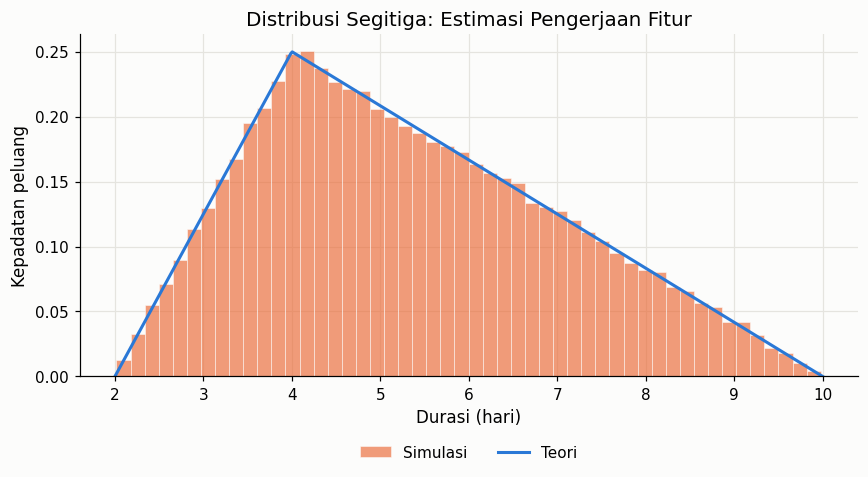

In [29]:
# Pada SciPy, c = (paling mungkin - minimum) / (maksimum - minimum)
durasi = stats.triang(c=(4 - 2) / (10 - 2), loc=2, scale=10 - 2)
sampel = rng.triangular(2, 4, 10, size=N)

tabel_banding([
    ["P(X > 7)", 9 / 48, durasi.sf(7), (sampel > 7).mean()],
    ["E[X]", 16 / 3, durasi.mean(), sampel.mean()],
    ["Var(X)", 52 / 18, durasi.var(), sampel.var()],
])
grafik_kontinu(durasi, sampel, np.linspace(2, 10, 500), "Distribusi Segitiga: Estimasi Pengerjaan Fitur", "Durasi (hari)")

# Bagian C: Bonus

## C1. Teorema Limit Pusat: Rata-Rata Waktu Proses

**Soal:** Waktu proses berdistribusi eksponensial dengan rata-rata 2 detik. Diambil rata-rata dari 40 data, lalu proses ini diulang 100.000 kali. Bandingkan hasilnya dengan distribusi normal dan hitung $P(\bar{X}>2{,}5)$.

**Hitungan manual:** Menurut Teorema Limit Pusat, untuk $n$ yang cukup besar berlaku:

$$\bar{X}\approx N\left(\mu,\frac{\sigma^2}{n}\right)=N\left(2,\frac{4}{40}\right)=N(2;\,0{,}1)$$

$$z=\frac{2{,}5-2}{\sqrt{0{,}1}}\approx1{,}5811 \qquad P(\bar{X}>2{,}5)\approx1-\Phi(1{,}5811)\approx0{,}0569$$

In [30]:
# Populasi asli dan rata-rata 40 data
populasi = rng.exponential(2, size=N)
rata_rata = rng.exponential(2, size=(N, 40)).mean(axis=1)

# Pendekatan normal menurut Teorema Limit Pusat
pendekatan = stats.norm(loc=2, scale=math.sqrt(4 / 40))

tabel_banding([
    ["P(rata-rata > 2,5)", 0.0569, pendekatan.sf(2.5), (rata_rata > 2.5).mean()],
    ["Rata-rata", 2, pendekatan.mean(), rata_rata.mean()],
    ["Varians", 0.1, pendekatan.var(), rata_rata.var()],
])

,Besaran,Manual,Python,Simulasi,Selisih
0,"P(rata-rata > 2,5)",0.0569,0.0569,0.0638,0.0069
1,Rata-rata,2.0000,2.0000,1.9995,0.0005
2,Varians,0.1000,0.1000,0.0994,0.0006


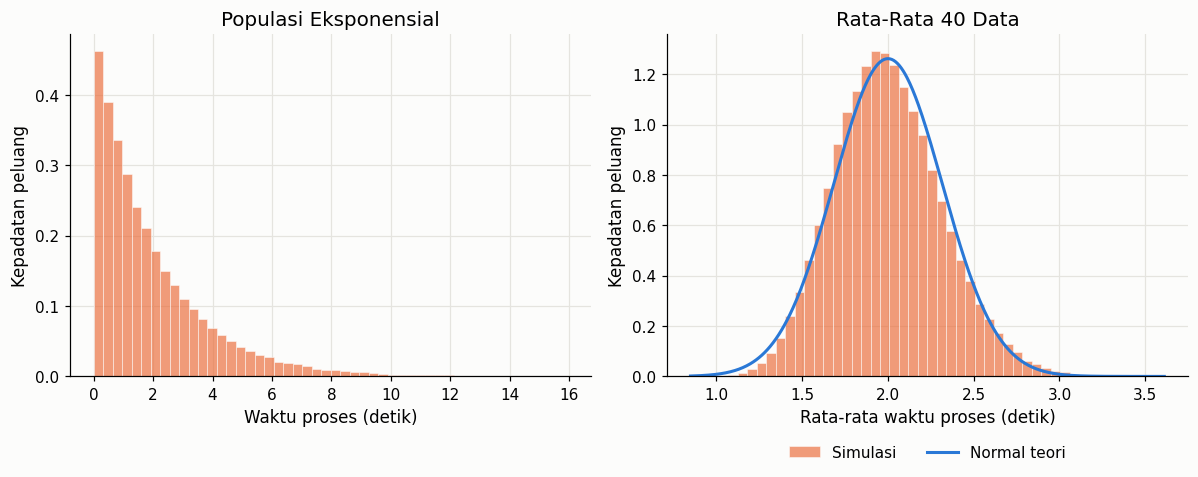

In [31]:
# Membandingkan bentuk populasi dengan bentuk rata-rata sampel
fig, sumbu = plt.subplots(1, 2, figsize=(11, 4.5))

sumbu[0].hist(populasi[populasi <= 16], bins=50, density=True, color=WARNA_SIMULASI, alpha=0.65,
              edgecolor="#fcfcfb", linewidth=0.5)
sumbu[0].set(title="Populasi Eksponensial", xlabel="Waktu proses (detik)", ylabel="Kepadatan peluang")

nilai_x = np.linspace(rata_rata.min(), rata_rata.max(), 500)
sumbu[1].hist(rata_rata, bins=50, density=True, color=WARNA_SIMULASI, alpha=0.65,
              edgecolor="#fcfcfb", linewidth=0.5, label="Simulasi")
sumbu[1].plot(nilai_x, pendekatan.pdf(nilai_x), color=WARNA_TEORI, linewidth=2, label="Normal teori")
sumbu[1].set(title="Rata-Rata 40 Data", xlabel="Rata-rata waktu proses (detik)", ylabel="Kepadatan peluang")
sumbu[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

plt.tight_layout()
plt.show()

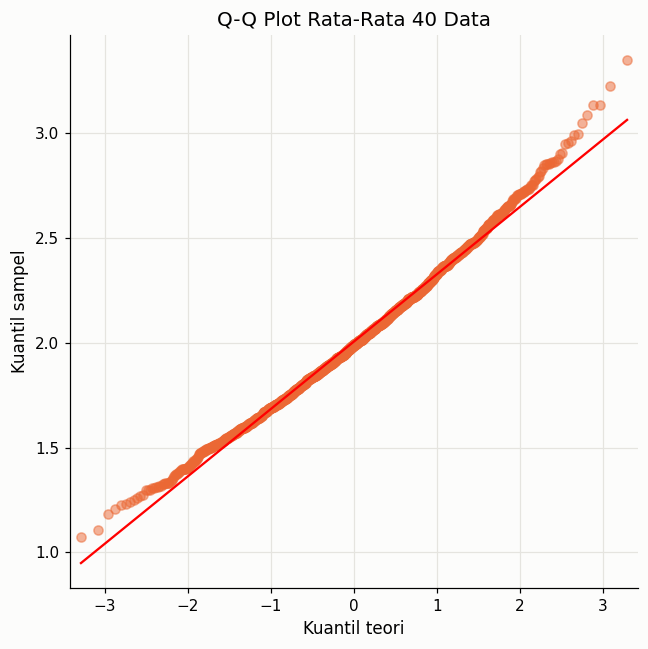

In [32]:
# Q-Q plot memakai 2.000 data agar grafik tetap ringan
fig, ax = plt.subplots(figsize=(6, 6))
sm.qqplot(rata_rata[:2000], line="s", ax=ax, markerfacecolor=WARNA_SIMULASI,
          markeredgecolor=WARNA_SIMULASI, alpha=0.5)
ax.set(title="Q-Q Plot Rata-Rata 40 Data", xlabel="Kuantil teori", ylabel="Kuantil sampel")
plt.tight_layout()
plt.show()